[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/NavaSergio/SP1-material-estudiantes/blob/main/docs/U4-BD/material/04_ejemplo_fraude_transacciones.ipynb)

# Ejemplo de punta a punta 3: fraude en transacciones (de la pregunta de la U3 a la base de datos)

**Seminario de Proyecto I (MCDI) — Unidad 4: Diseño de bases de datos y recolección de información**

Los dos ejemplos anteriores partían de datos que ya existían. Aquí recorremos **el camino que debe seguir tu proyecto**: partimos de la **pregunta, los objetivos y las hipótesis** del ejemplo de detección de fraude de la Unidad 3 (cuyo planteamiento viene de la Unidad 2) y los convertimos, paso a paso, en una **base de datos** con su diccionario.

> **Los datos de este notebook son simulados.** No existe un conjunto público con las variables que pide esa pregunta (monto, ubicación, dispositivo, horario, historial). Los generamos con un procedimiento transparente y reproducible, e **incluimos a propósito problemas típicos** de datos reales (duplicados, montos inválidos, ciudades escritas de varias formas...). Como sabemos qué sembramos, podemos **comprobar** que la limpieza los encontró. **No se pueden sacar conclusiones sobre fraude real** de estos datos: el objetivo es validar la **estructura y la calidad** de la base.

| Paso | Qué hacemos | Diapositivas relacionadas |
|---|---|---|
| 1 | Del planteamiento a la pregunta, los objetivos y las hipótesis | De la pregunta a la base para análisis |
| 2 | Operacionalización: de cada hipótesis a una variable medible | De variables a organización de datos |
| 3 | Diseño: ¿una tabla o varias? | Primera estructura; ¿Una tabla o múltiples tablas?; Cuando una tabla no basta |
| 4 | Plan de recolección y muestreo | ¿De dónde obtengo mis datos?; Muestreo |
| 5 | La "extracción" simulada y sus problemas | Evaluación del origen de los datos |
| 6 | Diagnóstico y limpieza, con registro de lo excluido | Control de calidad de los datos |
| 7 | Base relacional en SQLite y tabla de análisis | Cuando una tabla no basta |
| 8 | Variables derivadas de las hipótesis (sin fuga de información) | Imputación; De datos crudos a datos listos |
| 9 | Etiquetas tardías, división temporal y agregación | Agregación |
| 10 | Fuga de información: el error que parece éxito | Imputación (aviso de *data leakage*) |
| 11 | Entregables: diccionario, esquema y README | Diccionario de datos; Organización de archivos |
| 12 | ¿La base permite contrastar las hipótesis? | Lista de buenas prácticas |

**Cómo usarlo.** Funciona en Google Colab o en tu computadora (`pip install -r requirements.txt`). **No necesita internet ni descargas**: genera los datos y crea la carpeta `proyecto_fraude/` con la estructura recomendada. Tarda menos de un minuto.

> Este es un *ejemplo*, no una plantilla. Lo que debes replicar es el **razonamiento**: pregunta → hipótesis → variable → estructura → calidad → documentación.

In [1]:
from pathlib import Path
import sqlite3
import unicodedata

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pd.options.display.float_format = "{:.2f}".format
pd.options.display.max_columns = 30
pd.options.display.width = 140
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

SEMILLA = 2026   # con la misma semilla se obtienen siempre los mismos datos simulados

# Estructura de carpetas recomendada en la presentación
RAIZ = Path("proyecto_fraude")
for sub in ["datos/originales", "datos/procesados", "documentos"]:
    (RAIZ / sub).mkdir(parents=True, exist_ok=True)
print("Carpetas listas en:", RAIZ)

Carpetas listas en: proyecto_fraude


## 1. Del planteamiento a la pregunta, los objetivos y las hipótesis

**Planteamiento (Unidad 2).** El fraude financiero provoca pérdidas crecientes; los métodos tradicionales producen muchos falsos positivos y no siempre se adaptan a patrones nuevos. Falta evidencia sobre **qué características de la transacción y del usuario permiten detectarlo a tiempo**.

**Pregunta general (Unidad 3).** ¿Qué factores permiten identificar de manera temprana las transacciones financieras fraudulentas en plataformas digitales?

**Objetivo general.** Analizar los factores transaccionales y de usuario que inciden en la detección de transacciones financieras fraudulentas, utilizando modelos de ciencia de datos.

**Hipótesis general.** La integración de variables transaccionales y de usuario en modelos de aprendizaje automático permite mejorar significativamente la detección de fraudes financieros.

**Matriz de coherencia.** Es el puente entre la Unidad 3 y la Unidad 4: cada pregunta específica con su objetivo, su hipótesis y **lo que tendrá que existir en la base** para contrastarla.

| Pregunta específica | Objetivo específico | Hipótesis específica | Variables que debe contener la base | Rol |
|---|---|---|---|---|
| ¿Qué variables transaccionales (monto, frecuencia, ubicación) se asocian con patrones de fraude? | **OE1.** Identificar variables clave asociadas con la ocurrencia de transacciones fraudulentas | **H1.** Las transacciones con montos atípicos y ubicaciones inusuales tienen mayor probabilidad de ser fraudulentas | `monto_z_cliente`, `ubicacion_inusual`, `n_trans_24h` | Independientes (derivadas) |
| ¿Cómo influyen las características del usuario (historial, dispositivo, horario) en la probabilidad de fraude? | **OE2.** Evaluar la relación entre las características del usuario y la probabilidad de fraude | **H2.** Los usuarios con historiales irregulares y accesos desde dispositivos no habituales presentan mayor riesgo de fraude | `tiene_contracargo_previo`, `dispositivo_nuevo`, `es_madrugada` | Independientes (derivadas) |
| ¿Qué algoritmos de aprendizaje automático ofrecen mayor precisión en la clasificación? | **OE3.** Comparar el desempeño de distintos algoritmos de clasificación | **H3.** Los algoritmos basados en ensambles superan en precisión a los modelos lineales | Todas las anteriores y la variable a explicar `es_fraude_confirmado` | Dependiente |

> **Observación clave.** Ninguna hipótesis menciona una columna: hablan de "montos atípicos", "ubicaciones inusuales", "historiales irregulares". La Unidad 4 empieza justo ahí: **traducir cada concepto a una variable que se pueda medir y registrar**.

## 2. Operacionalización: de cada concepto a una variable medible

Para cada concepto de las hipótesis definimos **la variable, la regla exacta que la produce, su escala y de qué sistema sale**. Esta tabla es el núcleo del diccionario de datos que armaremos al final.

| Concepto en la hipótesis | Variable | Regla (indicador) | Escala | Sistema de origen |
|---|---|---|---|---|
| Transacción fraudulenta (**variable a explicar**) | `es_fraude_confirmado` | 1 si la transacción aparece en la tabla de contracargos (el banco confirmó el fraude); 0 en otro caso | Binaria | Contracargos |
| Monto atípico | `monto_z_cliente` | Cuántas desviaciones estándar se aleja el logaritmo del monto de lo que el cliente **ya había gastado antes**; se calcula con al menos 5 transacciones previas | Continua | Transacciones |
| Ubicación inusual | `ubicacion_inusual` | La ciudad de la transacción es distinta de la ciudad habitual del cliente | Binaria | Transacciones y clientes |
| Frecuencia | `n_trans_24h` | Transacciones previas del mismo cliente en las 24 horas anteriores | Conteo | Transacciones |
| Historial irregular | `tiene_contracargo_previo` | El cliente tiene al menos un contracargo **confirmado antes** de esta transacción | Binaria | Contracargos |
| Dispositivo no habitual | `dispositivo_nuevo` | Compra en línea con un dispositivo que el cliente no había usado antes | Binaria | Transacciones |
| Horario | `hora_del_dia`, `es_madrugada` | Hora de la transacción; madrugada = de 0 a 5 h | Entero / binaria | Transacciones |

Dos decisiones de diseño que aparecen aquí y que se repiten en cualquier proyecto:

1. **Operacionalizar es aproximar.** "Dispositivo no habitual" se mide como "dispositivo nunca visto antes", que también marca como nuevo el segundo dispositivo legítimo de un cliente. Hay que **registrar** esa limitación.
2. **Solo información disponible en el momento.** Para detectar fraude "de manera temprana", cada variable debe calcularse **solo con lo que se sabía cuando ocurrió la transacción**. Por eso las reglas dicen "previas", "anteriores", "confirmado antes". Si no, el modelo usaría información del futuro (lo veremos en la sección 10).

## 3. Diseño: ¿una tabla o varias?

**El análisis necesita una sola tabla:** una fila por **transacción** (la unidad de análisis), con sus variables en columnas. Es el punto de partida y el destino.

**Pero los datos no nacen así.** En un banco vienen de **cuatro sistemas**, y hay razones concretas para conservarlos separados antes de integrarlos:

- Los atributos del **cliente** (segmento, ciudad habitual) y de la **tienda** (ciudad, giro) se repetirían miles de veces en una tabla plana.
- La **etiqueta de fraude llega de otro sistema y con retraso**: el contracargo se confirma días o semanas después de la compra.
- Un modelo relacional permite que el DBMS **rechace datos inválidos** (tiendas inexistentes, montos no positivos, identificadores repetidos).

```
  clientes (1) ───────<  transacciones  >─────── (1) tiendas
  PK id_cliente           PK id_transaccion         PK id_tienda
                          FK id_cliente
                          FK id_tienda
                               │
                               │ (1)
                               ▼ (0..1)
                          contracargos
                          PK, FK id_transaccion
```

Cada transacción tiene **cero o un** contracargo. Usaremos **SQLite** como sistema gestor de bases de datos (DBMS): no requiere instalar un servidor y es suficiente para este tamaño. El plan es: **cargar los cuatro sistemas en SQLite → integrarlos con una consulta SQL → obtener la tabla plana de análisis**.

## 4. Plan de recolección y muestreo

Antes de generar datos fijamos, como lo haría un proyecto real, **qué vamos a observar**:

| Decisión | En este ejemplo |
|---|---|
| **Población** | Las transacciones con tarjeta de los clientes activos de un banco |
| **Marco muestral** | La lista de clientes activos del banco |
| **Diseño de muestreo** | **Por conglomerados**: se eligen 2,000 clientes al azar y se toman **todas** sus transacciones |
| **Periodo** | Del 1 de octubre de 2025 al 30 de septiembre de 2026 |
| **Unidad de selección vs. unidad de análisis** | Se selecciona al *cliente*, pero cada fila es una *transacción*: las transacciones de un mismo cliente **no son independientes** |
| **Fuentes** | Cuatro sistemas: clientes, tiendas, transacciones y contracargos |
| **Fecha de extracción** | 1 de octubre de 2026 |
| **Fenómeno raro** | El fraude es una fracción pequeña de las transacciones (menos de 2 %): conviene fijar de antemano cuántos casos positivos se necesitan |

**Por qué importa el muestreo por conglomerados:** si luego dividimos los datos al azar por transacción, las compras de un mismo cliente caerían en entrenamiento y prueba a la vez. Por eso usaremos una **división temporal** (sección 9).

## 5. La "extracción" simulada y sus problemas

Esta celda **simula** lo que el banco entregaría. Está pensada para leerse: define cómo se comportan los clientes, las tiendas y el fraude, y después **siembra problemas** en los archivos que "entrega" cada sistema. Registramos en `VERDAD` cuántos problemas sembramos para comprobar luego que el diagnóstico los detecta (esto, en datos reales, no existe).

El fraude se genera con un mecanismo de riesgo que aumenta con el monto atípico, la ubicación inusual, el dispositivo nuevo y la madrugada, y además **ocurre en ráfagas** (tras una compra fraudulenta, el atacante repite varias en las horas siguientes): **por eso las hipótesis H1 y H2 tendrán cierto respaldo en los datos**. Es consecuencia de cómo los simulamos, no un hallazgo.

In [2]:
rng = np.random.default_rng(SEMILLA)

INICIO, FIN = pd.Timestamp("2025-10-01"), pd.Timestamp("2026-09-30")
FECHA_EXTRACCION = pd.Timestamp("2026-10-01")
N_CLIENTES, N_FISICAS, N_LINEA = 2000, 100, 20
PREVALENCIA = 0.009          # proporción de "fraudes iniciales" (con las ráfagas, el total será cercano al doble)
VENTANA_MADUREZ_DIAS = 60    # los contracargos tardan hasta 60 días en confirmarse
FECHA_MADUREZ = FECHA_EXTRACCION - pd.DateOffset(days=VENTANA_MADUREZ_DIAS)

CIUDADES = ["Ciudad de México", "Guadalajara", "Monterrey", "Puebla", "Querétaro", "Mérida", "Tijuana", "León"]
P_CIUDAD = np.array([.30, .15, .15, .08, .08, .06, .09, .09])
P_CIUDAD = P_CIUDAD / P_CIUDAD.sum()

# ---- Clientes (sistema 1) ----
segmento = rng.choice(["básico", "preferente", "premium"], N_CLIENTES, p=[.55, .35, .10])
mu = np.select([segmento == "básico", segmento == "preferente"], [5.6, 6.1], 6.7) + rng.normal(0, .3, N_CLIENTES)
sigma = rng.uniform(.4, .8, N_CLIENTES)          # variabilidad del gasto de cada cliente
vulnerable = rng.normal(0, 1, N_CLIENTES)        # propensión del cliente a ser víctima
ciudad_hab = rng.choice(CIUDADES, N_CLIENTES, p=P_CIUDAD)
n_disp = rng.integers(1, 4, N_CLIENTES)          # dispositivos habituales (1 a 3)
alta = pd.Timestamp("2018-01-01") + pd.to_timedelta(
    rng.integers(0, (pd.Timestamp("2025-09-30") - pd.Timestamp("2018-01-01")).days, N_CLIENTES), unit="D")
clientes_fuente = pd.DataFrame({
    "id_cliente": [f"C{i:04d}" for i in range(1, N_CLIENTES + 1)],
    "segmento_cliente": segmento,
    "fecha_alta": alta.strftime("%Y-%m-%d"),
    "ciudad_habitual": ciudad_hab,
})

# ---- Tiendas (sistema 2) ----
ciudad_fisicas = np.concatenate([np.array(CIUDADES), rng.choice(CIUDADES, N_FISICAS - len(CIUDADES), p=P_CIUDAD)])
tiendas_fuente = pd.DataFrame({
    "id_tienda": [f"T{i:03d}" for i in range(1, N_FISICAS + N_LINEA + 1)],
    "ciudad_tienda": np.concatenate([ciudad_fisicas, rng.choice(CIUDADES, N_LINEA, p=P_CIUDAD)]),
    "giro": np.concatenate([
        rng.choice(["supermercado", "restaurante", "gasolinera", "ropa", "farmacia"], N_FISICAS),
        rng.choice(["comercio electrónico", "servicios digitales"], N_LINEA),
    ]),
})
tienda_en_linea = np.arange(len(tiendas_fuente)) >= N_FISICAS

# ---- Transacciones (sistema 3) ----
n_i = 1 + rng.poisson(rng.lognormal(np.log(22), .6, N_CLIENTES))
cli = np.repeat(np.arange(N_CLIENTES), n_i)
N = len(cli)

P_HORA = np.array([.5, .3, .2, .2, .3, .6, 1.5, 2.5, 3, 3.5, 4, 4.5, 6, 6.5, 6, 5, 4.5, 5, 6, 6.5, 5.5, 3.5, 2.5, 1.2])
P_HORA = P_HORA / P_HORA.sum()
dias = rng.integers(0, (FIN - INICIO).days + 1, N)
hora = rng.choice(24, N, p=P_HORA)
fecha_hora = (INICIO + pd.to_timedelta(dias, unit="D") + pd.to_timedelta(hora, unit="h")
              + pd.to_timedelta(rng.integers(0, 3600, N), unit="s"))
en_linea = rng.random(N) < .35

# ciudad de la transacción: casi siempre la habitual
fuera = rng.random(N) < np.where(en_linea, .08, .07)
otra = rng.choice(CIUDADES, N, p=P_CIUDAD)
ciudad_tx = np.where(fuera & (otra != ciudad_hab[cli]), otra, ciudad_hab[cli])
ubicacion_real = ciudad_tx != ciudad_hab[cli]

# tienda: física en la ciudad de la compra; en línea, una tienda digital
tienda_idx = np.empty(N, dtype=int)
for c in CIUDADES:
    candidatas = np.flatnonzero((tiendas_fuente["ciudad_tienda"].to_numpy() == c) & ~tienda_en_linea)
    m = (~en_linea) & (ciudad_tx == c)
    tienda_idx[m] = rng.choice(candidatas, m.sum())
tienda_idx[en_linea] = rng.choice(np.flatnonzero(tienda_en_linea), en_linea.sum())

# monto: cada cliente gasta en torno a su propio nivel
z = rng.normal(0, 1, N)
monto = np.exp(mu[cli] + .2 * en_linea + sigma[cli] * z).round(2).clip(min=5)

# dispositivo: solo existe en compras en línea (en tienda física no se registra)
es_habitual = rng.random(N) < .95
disp_habitual = np.array([f"D{c + 1:04d}{k}" for c, k in zip(cli, rng.integers(0, n_disp[cli]))])
disp_nuevo = np.array([f"D{x}" for x in rng.integers(10**6, 10**7, N)])
dispositivo = np.where(en_linea, np.where(es_habitual, disp_habitual, disp_nuevo), None)
dispositivo_nuevo_real = en_linea & ~es_habitual
madrugada = hora <= 5

# mecanismo de fraude: riesgo logístico; el intercepto se ajusta para lograr la prevalencia deseada
def riesgo(b0):
    lg = (b0 + .7 * np.clip(z, -3, 4) + 1.7 * ubicacion_real + 1.9 * dispositivo_nuevo_real
          + 1.0 * madrugada + .8 * en_linea + .5 * vulnerable[cli])
    return 1 / (1 + np.exp(-lg))

bajo, alto = -15.0, 0.0
for _ in range(60):
    medio = (bajo + alto) / 2
    bajo, alto = (bajo, medio) if riesgo(medio).mean() > PREVALENCIA else (medio, alto)
es_fraude_real = rng.random(N) < riesgo((bajo + alto) / 2)

# el banco confirma el fraude días o semanas después de la compra
rezago_dias = np.clip(rng.gamma(4, 4, N) + 2, 2, 60)
fecha_confirmacion = fecha_hora + pd.to_timedelta(rezago_dias, unit="D")

tx_sim = pd.DataFrame({
    "fecha_hora": fecha_hora, "id_cliente": clientes_fuente["id_cliente"].to_numpy()[cli],
    "id_tienda": tiendas_fuente["id_tienda"].to_numpy()[tienda_idx],
    "canal": np.where(en_linea, "en línea", "presencial"), "ciudad_transaccion": ciudad_tx,
    "id_dispositivo": dispositivo, "monto": monto,
    "_fraude": es_fraude_real, "_confirmacion": fecha_confirmacion,
})

# los fraudes suelen venir en ráfagas: tras una compra fraudulenta, el atacante repite 1 a 3 en las horas siguientes
inicio_rafaga = tx_sim[tx_sim["_fraude"]].sample(frac=.45, random_state=SEMILLA)
extra = inicio_rafaga.loc[inicio_rafaga.index.repeat(rng.integers(1, 4, len(inicio_rafaga)))].copy()
extra["fecha_hora"] = extra["fecha_hora"] + pd.to_timedelta(rng.integers(5, 180, len(extra)), unit="m")
extra["monto"] = (extra["monto"] * rng.uniform(.6, 1.4, len(extra))).round(2).clip(lower=5)
extra = extra[extra["fecha_hora"] < FECHA_EXTRACCION]
tx_sim = pd.concat([tx_sim, extra]).sort_values("fecha_hora").reset_index(drop=True)
tx_sim.insert(0, "id_transaccion", [f"TX{i:07d}" for i in range(1, len(tx_sim) + 1)])

# ---- Contracargos (sistema 4): solo los fraudes ya confirmados el día de la extracción ----
confirmados = tx_sim[tx_sim["_fraude"] & (tx_sim["_confirmacion"] <= FECHA_EXTRACCION)]
contracargos_fuente = pd.DataFrame({
    "id_transaccion": confirmados["id_transaccion"],
    "fecha_confirmacion": confirmados["_confirmacion"].dt.strftime("%Y-%m-%d"),
})
fraude_total_real = int(tx_sim["_fraude"].sum())
tx_fuente = tx_sim.drop(columns=["_fraude", "_confirmacion"]).copy()
tx_fuente["fecha_hora"] = tx_fuente["fecha_hora"].dt.strftime("%Y-%m-%d %H:%M:%S")

# ---- Problemas sembrados en lo que "entregan" los sistemas ----
VERDAD = {}
variantes = {
    "Ciudad de México": ["CDMX", "ciudad de mexico", "CIUDAD DE MÉXICO "], "Guadalajara": ["GDL", "guadalajara", "GUADALAJARA "],
    "Monterrey": ["MTY", "monterrey", "Monterrey "], "Puebla": ["puebla", "PUEBLA "],
    "Querétaro": ["queretaro", "Queretaro ", "QUERÉTARO"], "Mérida": ["merida", "MERIDA "],
    "Tijuana": ["tijuana", "TIJUANA "], "León": ["leon", "LEON "],
}
m = rng.random(len(tx_fuente)) < .03
tx_fuente.loc[m, "ciudad_transaccion"] = [rng.choice(variantes[c]) for c in tx_fuente.loc[m, "ciudad_transaccion"]]
VERDAD["ciudad escrita de otra forma"] = int(m.sum())

m = rng.random(len(tx_fuente)) < .003
tx_fuente.loc[m, "monto"] = -tx_fuente.loc[m, "monto"]
VERDAD["monto negativo"] = int(m.sum())

m = rng.random(len(tx_fuente)) < .002
tx_fuente.loc[m, "id_tienda"] = "T999"
VERDAD["tienda que no existe en el catálogo"] = int(m.sum())

repetidas = tx_fuente.sample(frac=.004, random_state=SEMILLA)
tx_fuente = pd.concat([tx_fuente, repetidas]).sample(frac=1, random_state=SEMILLA).reset_index(drop=True)
VERDAD["filas duplicadas (copias exactas)"] = len(repetidas)

m = rng.random(N_CLIENTES) < .03
clientes_fuente.loc[m, "segmento_cliente"] = np.nan
VERDAD["clientes sin segmento"] = int(m.sum())

# ---- "Lo que entrega cada sistema": archivos originales (no se modifican después) ----
clientes_fuente.to_csv(RAIZ / "datos/originales/clientes.csv", index=False)
tiendas_fuente.to_csv(RAIZ / "datos/originales/tiendas.csv", index=False)
tx_fuente.to_csv(RAIZ / "datos/originales/transacciones.csv", index=False)
contracargos_fuente.to_csv(RAIZ / "datos/originales/contracargos.csv", index=False)
(RAIZ / "datos/originales/origen.txt").write_text(
    "Datos SIMULADOS con el notebook 04_ejemplo_fraude_transacciones (semilla "
    f"{SEMILLA}).\nExtracción simulada al {FECHA_EXTRACCION:%Y-%m-%d}. No corresponden a ninguna persona ni institución real.\n",
    encoding="utf-8")

print("Archivos originales creados en", RAIZ / "datos/originales")
for nombre, df in [("clientes", clientes_fuente), ("tiendas", tiendas_fuente),
                   ("transacciones", tx_fuente), ("contracargos", contracargos_fuente)]:
    print(f"  {nombre:14s} {df.shape[0]:>6,} filas x {df.shape[1]} columnas")

Archivos originales creados en proyecto_fraude/datos/originales
  clientes        2,000 filas x 4 columnas
  tiendas           120 filas x 3 columnas
  transacciones  54,745 filas x 8 columnas
  contracargos      850 filas x 2 columnas


**¿Cuántos casos necesito?** Con un fenómeno raro, lo que limita la precisión no es el número de transacciones sino el de **fraudes**. Veamos qué pasaría si, en lugar de tomar todas las transacciones, hubiéramos usado una muestra aleatoria simple de distintos tamaños:

In [3]:
# Prevalencia observada en lo que se extrajo (con la etiqueta disponible el día de la extracción)
n_total = tx_sim["id_transaccion"].nunique()
p_obs = len(contracargos_fuente) / n_total

def wilson(p, n, z=1.96):
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    mitad = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centro - mitad, centro + mitad

filas = []
for n in [500, 2_000, 10_000, n_total]:
    bajo_ic, alto_ic = wilson(p_obs, n)
    filas.append({"transacciones en la muestra": n, "fraudes esperados": round(n * p_obs),
                  "IC 95% de la tasa de fraude (%)": f"{100 * bajo_ic:.2f} a {100 * alto_ic:.2f}"})
pd.DataFrame(filas)

,transacciones en la muestra,fraudes esperados,IC 95% de la tasa de fraude (%)
0,500,8,0.79 a 3.07
1,2000,31,1.10 a 2.20
2,10000,156,1.33 a 1.82
3,54527,850,1.46 a 1.67


Con 500 transacciones se esperan menos de 10 fraudes y el intervalo es muy ancho: **no alcanzaría ni para estimar la tasa**, mucho menos para entrenar un modelo. Por eso en fenómenos raros se toman **todos** los casos positivos y se documenta cómo se eligió el resto.

> **Nota sobre las etiquetas.** La tasa que acabamos de usar es la de los fraudes **ya confirmados**. Más adelante veremos que subestima la real, porque los fraudes recientes aún no se han confirmado.

## 6. Diagnóstico y limpieza

Empezamos como lo haría un analista: **leyendo los archivos originales** (no los objetos de la celda anterior) y haciendo un diagnóstico antes de tocar nada. Los originales de `datos/originales/` **no se modifican nunca**; toda corrección se hace en memoria y queda registrada.

In [4]:
clientes = pd.read_csv(RAIZ / "datos/originales/clientes.csv")
tiendas = pd.read_csv(RAIZ / "datos/originales/tiendas.csv")
tx_crudo = pd.read_csv(RAIZ / "datos/originales/transacciones.csv")
contracargos = pd.read_csv(RAIZ / "datos/originales/contracargos.csv")

print(tx_crudo.dtypes.to_string(), "\n")
tx_crudo.head()

id_transaccion         object
fecha_hora             object
id_cliente             object
id_tienda              object
canal                  object
ciudad_transaccion     object
id_dispositivo         object
monto                 float64 



,id_transaccion,fecha_hora,id_cliente,id_tienda,canal,ciudad_transaccion,id_dispositivo,monto
0,TX0001593,2025-10-11 08:37:57,C0019,T016,presencial,Ciudad de México,NaN,360.92
1,TX0000823,2025-10-06 11:38:18,C0565,T090,presencial,Monterrey,NaN,321.73
2,TX0023673,2026-03-07 21:47:57,C0343,T112,en línea,Monterrey,D03430,428.83
3,TX0005440,2025-11-05 11:52:08,C1948,T103,en línea,Tijuana,D9518935,464.12
4,TX0031434,2026-04-28 19:46:34,C1713,T039,presencial,Monterrey,NaN,191.31


In [5]:
catalogo_ciudades = sorted(clientes["ciudad_habitual"].unique())

diagnostico = pd.DataFrame([
    ("Filas repetidas (copia exacta)", int(tx_crudo.duplicated().sum()), len(tx_crudo)),
    ("id_transaccion repetido", int(tx_crudo["id_transaccion"].duplicated().sum()), len(tx_crudo)),
    ("Monto menor o igual que cero", int((tx_crudo["monto"] <= 0).sum()), len(tx_crudo)),
    ("id_tienda que no está en el catálogo de tiendas", int((~tx_crudo["id_tienda"].isin(tiendas["id_tienda"])).sum()), len(tx_crudo)),
    ("id_cliente que no está en el catálogo de clientes", int((~tx_crudo["id_cliente"].isin(clientes["id_cliente"])).sum()), len(tx_crudo)),
    ("Ciudad escrita fuera del catálogo", int((~tx_crudo["ciudad_transaccion"].isin(catalogo_ciudades)).sum()), len(tx_crudo)),
    ("Clientes sin segmento", int(clientes["segmento_cliente"].isna().sum()), len(clientes)),
    ("Contracargos sin transacción asociada", int((~contracargos["id_transaccion"].isin(tx_crudo["id_transaccion"])).sum()), len(contracargos)),
], columns=["revisión", "filas afectadas", "de un total de"])
diagnostico["% afectado"] = (100 * diagnostico["filas afectadas"] / diagnostico["de un total de"]).round(2)
diagnostico

,revisión,filas afectadas,de un total de,% afectado
0,Filas repetidas (copia exacta),218,54745,0.40
1,id_transaccion repetido,218,54745,0.40
2,Monto menor o igual que cero,178,54745,0.33
3,id_tienda que no está en el catálogo de tiendas,97,54745,0.18
4,id_cliente que no está en el catálogo de clientes,0,54745,0.00
5,Ciudad escrita fuera del catálogo,1631,54745,2.98
6,Clientes sin segmento,53,2000,2.65
7,Contracargos sin transacción asociada,0,850,0.00


Una distinción más que debe hacer el diagnóstico: **no todo faltante es un error**. Veamos el dispositivo según el canal:

In [6]:
pd.crosstab(tx_crudo["canal"], tx_crudo["id_dispositivo"].isna(),
            rownames=["canal"], colnames=["dispositivo vacío"])

dispositivo vacío,False,True
canal,,
en línea,19423,0
presencial,0,35322


El dispositivo **solo falta en las compras presenciales**: en una terminal física no se registra. Es un **faltante estructural** (la variable "no aplica"), no un dato perdido: **no se imputa**. Imputarlo inventaría dispositivos que no existieron.

Ahora aplicamos las correcciones, **una decisión a la vez**, y comprobamos contra lo que sembramos:

| Problema | Decisión | Por qué |
|---|---|---|
| Filas duplicadas | Eliminar las copias exactas | No aportan información y duplican el peso de esas transacciones |
| Ciudades con otra escritura | Normalizar a las ocho ciudades del catálogo | Es la misma ciudad; si no, "CDMX" y "Ciudad de México" parecerían lugares distintos y se crearían falsas "ubicaciones inusuales" |
| Monto no positivo | **Excluir y registrar** en un archivo aparte | Un monto debe ser positivo; no sabemos cuál era el valor correcto |
| Tienda inexistente | **Excluir y registrar** en un archivo aparte | La transacción no se puede unir al catálogo |
| Clientes sin segmento | Categoría `sin dato` (no la moda) | Rellenar con el segmento más común fingiría un dato que no tenemos |

In [7]:
import unicodedata

def clave(texto):
    # minúsculas, sin acentos y sin espacios sobrantes
    sin_acentos = "".join(c for c in unicodedata.normalize("NFD", str(texto)) if unicodedata.category(c) != "Mn")
    return sin_acentos.strip().casefold()

CANON = {clave(c): c for c in catalogo_ciudades}
CANON.update({"cdmx": "Ciudad de México", "gdl": "Guadalajara", "mty": "Monterrey"})   # abreviaturas conocidas

# 1. Duplicados
tx = tx_crudo.drop_duplicates().copy()
n_duplicadas = len(tx_crudo) - len(tx)

# 2. Ciudades: contamos antes de normalizar y fallamos si aparece una escritura desconocida
n_ciudades = int((~tx["ciudad_transaccion"].isin(catalogo_ciudades)).sum())
tx["ciudad_transaccion"] = tx["ciudad_transaccion"].map(lambda s: CANON[clave(s)])

# 3. Exclusiones con registro (no se borra en silencio)
monto_malo = tx["monto"] <= 0
tienda_mala = ~tx["id_tienda"].isin(tiendas["id_tienda"])
excluidas = tx[monto_malo | tienda_mala].copy()
excluidas["motivo"] = np.where(monto_malo[excluidas.index], "monto no positivo", "tienda inexistente")
excluidas.to_csv(RAIZ / "datos/procesados/transacciones_excluidas.csv", index=False)
tx = tx[~(monto_malo | tienda_mala)].copy()

# los contracargos de transacciones excluidas se quedan sin transacción: también se excluyen
n_contra_antes = len(contracargos)
contracargos = contracargos[contracargos["id_transaccion"].isin(tx["id_transaccion"])].copy()

# 4. Segmento faltante
n_sin_segmento = int(clientes["segmento_cliente"].isna().sum())
clientes["segmento_cliente"] = clientes["segmento_cliente"].fillna("sin dato")

# Comprobación contra lo sembrado (en datos reales no existe esta verificación)
verificacion = pd.DataFrame([
    ("filas duplicadas (copias exactas)", VERDAD["filas duplicadas (copias exactas)"], n_duplicadas),
    ("ciudad escrita de otra forma", VERDAD["ciudad escrita de otra forma"], n_ciudades),
    ("monto negativo", VERDAD["monto negativo"], int(monto_malo.sum())),
    ("tienda que no existe en el catálogo", VERDAD["tienda que no existe en el catálogo"], int(tienda_mala.sum())),
    ("clientes sin segmento", VERDAD["clientes sin segmento"], n_sin_segmento),
], columns=["problema", "sembrados", "detectados"])
verificacion["coinciden"] = verificacion["sembrados"] == verificacion["detectados"]
print(f"Transacciones: {len(tx_crudo):,} crudas -> {len(tx):,} tras la limpieza "
      f"({len(excluidas)} excluidas con registro; {n_contra_antes - len(contracargos)} contracargo(s) quedaron sin transacción y se excluyeron)")
verificacion

Transacciones: 54,745 crudas -> 54,253 tras la limpieza (274 excluidas con registro; 1 contracargo(s) quedaron sin transacción y se excluyeron)


,problema,sembrados,detectados,coinciden
0,filas duplicadas (copias exactas),218,218,True
1,ciudad escrita de otra forma,1626,1626,True
2,monto negativo,177,177,True
3,tienda que no existe en el catálogo,97,97,True
4,clientes sin segmento,53,53,True


Los problemas se encontraron todos y en la cantidad exacta. En un proyecto real **no tendrías esta columna "sembrados"**, y justamente por eso el diagnóstico debe ser sistemático: cada revisión de la tabla es una pregunta que le haces a los datos, y debes **registrar** lo que decides (aquí, en `transacciones_excluidas.csv` y en el diccionario).

## 7. Base relacional en SQLite y tabla de análisis

Creamos la base con su **esquema**: llaves primarias, llaves foráneas y reglas de validez (`CHECK`). Con `PRAGMA foreign_keys = ON`, SQLite hace cumplir las relaciones.

In [8]:
ruta_db = RAIZ / "datos/procesados/fraude.sqlite"
if ruta_db.exists():
    ruta_db.unlink()          # se reconstruye siempre desde los archivos originales
con = sqlite3.connect(ruta_db)
con.execute("PRAGMA foreign_keys = ON")

# El orden importa: primero las tablas "padre" y después las que las referencian
con.executescript('''
CREATE TABLE clientes (
    id_cliente        TEXT PRIMARY KEY,
    segmento_cliente  TEXT NOT NULL CHECK (segmento_cliente IN ('básico', 'preferente', 'premium', 'sin dato')),
    fecha_alta        TEXT NOT NULL,
    ciudad_habitual   TEXT NOT NULL
);
CREATE TABLE tiendas (
    id_tienda      TEXT PRIMARY KEY,
    ciudad_tienda  TEXT NOT NULL,
    giro           TEXT NOT NULL
);
CREATE TABLE transacciones (
    id_transaccion      TEXT PRIMARY KEY,
    fecha_hora          TEXT NOT NULL,
    id_cliente          TEXT NOT NULL REFERENCES clientes (id_cliente),
    id_tienda           TEXT NOT NULL REFERENCES tiendas (id_tienda),
    canal               TEXT NOT NULL CHECK (canal IN ('presencial', 'en línea')),
    ciudad_transaccion  TEXT NOT NULL,
    id_dispositivo      TEXT,
    monto               REAL NOT NULL CHECK (monto > 0)
);
CREATE TABLE contracargos (
    id_transaccion      TEXT PRIMARY KEY REFERENCES transacciones (id_transaccion),
    fecha_confirmacion  TEXT NOT NULL
);
''')

clientes.to_sql("clientes", con, if_exists="append", index=False)
tiendas.to_sql("tiendas", con, if_exists="append", index=False)
tx.to_sql("transacciones", con, if_exists="append", index=False)
contracargos.to_sql("contracargos", con, if_exists="append", index=False)
con.commit()

for tabla in ["clientes", "tiendas", "transacciones", "contracargos"]:
    print(f"{tabla:14s}", con.execute(f"SELECT COUNT(*) FROM {tabla}").fetchone()[0], "filas")
print("Violaciones de llaves foráneas:", con.execute("PRAGMA foreign_key_check").fetchall())

clientes       2000 filas
tiendas        120 filas
transacciones  54253 filas
contracargos   849 filas
Violaciones de llaves foráneas: []


**¿Por qué sirve el esquema?** Probemos qué pasaría si alguien intentara guardar los datos **sin limpiar**. El DBMS debe rechazarlos:

In [9]:
fila = tx.iloc[0].to_dict()
intentos = {
    "monto negativo": {**fila, "id_transaccion": "TX9999991", "monto": -50.0},
    "tienda que no existe": {**fila, "id_transaccion": "TX9999992", "id_tienda": "T999"},
    "canal con un valor no permitido": {**fila, "id_transaccion": "TX9999993", "canal": "telefónico"},
    "id_transaccion repetido": fila,
}
resultados = []
for nombre, datos in intentos.items():
    try:
        con.execute("INSERT INTO transacciones VALUES (:id_transaccion, :fecha_hora, :id_cliente, :id_tienda, "
                    ":canal, :ciudad_transaccion, :id_dispositivo, :monto)", datos)
        con.rollback()
        resultados.append((nombre, "ACEPTADA (el esquema no la detecta)"))
    except sqlite3.IntegrityError as error:
        resultados.append((nombre, f"rechazada: {error}"))
pd.DataFrame(resultados, columns=["intento de inserción", "resultado"])

,intento de inserción,resultado
0,monto negativo,rechazada: CHECK constraint failed: monto > 0
1,tienda que no existe,rechazada: FOREIGN KEY constraint failed
2,canal con un valor no permitido,rechazada: CHECK constraint failed: canal IN (...
3,id_transaccion repetido,rechazada: UNIQUE constraint failed: transacci...


Las reglas del esquema son una **segunda línea de defensa**: no sustituyen el diagnóstico (el DBMS no sabe que "CDMX" y "Ciudad de México" son lo mismo), pero evitan que se cuelen errores estructurales.

Ahora **integramos** las cuatro tablas en la tabla plana de análisis con una consulta SQL: una fila por transacción, con los datos del cliente y de la tienda y la marca de si el banco confirmó el fraude. `LEFT JOIN` es esencial: las transacciones **sin** contracargo (la gran mayoría) deben seguir apareciendo.

In [10]:
consulta = '''
SELECT t.id_transaccion, t.fecha_hora, t.id_cliente, t.id_tienda, t.canal, t.ciudad_transaccion,
       t.id_dispositivo, t.monto,
       c.segmento_cliente, c.fecha_alta, c.ciudad_habitual,
       s.ciudad_tienda, s.giro,
       CASE WHEN x.id_transaccion IS NULL THEN 0 ELSE 1 END AS es_fraude_confirmado,
       x.fecha_confirmacion
FROM transacciones t
JOIN clientes c USING (id_cliente)
JOIN tiendas s USING (id_tienda)
LEFT JOIN contracargos x USING (id_transaccion)
'''
base = pd.read_sql_query(consulta, con, parse_dates=["fecha_hora", "fecha_alta", "fecha_confirmacion"])

# Validación: la integración no debe perder ni multiplicar filas
assert len(base) == len(tx), "El JOIN cambió el número de transacciones"
assert base["id_transaccion"].is_unique
print(f"Tabla plana: {base.shape[0]:,} filas x {base.shape[1]} columnas (una fila = una transacción)")
base.head(3)

Tabla plana: 54,253 filas x 15 columnas (una fila = una transacción)


,id_transaccion,fecha_hora,id_cliente,id_tienda,canal,ciudad_transaccion,id_dispositivo,monto,segmento_cliente,fecha_alta,ciudad_habitual,ciudad_tienda,giro,es_fraude_confirmado,fecha_confirmacion
0,TX0001593,2025-10-11 08:37:57,C0019,T016,presencial,Ciudad de México,None,360.92,básico,2024-11-13,Monterrey,Ciudad de México,supermercado,0,NaT
1,TX0000823,2025-10-06 11:38:18,C0565,T090,presencial,Monterrey,None,321.73,básico,2019-01-22,Monterrey,Monterrey,gasolinera,0,NaT
2,TX0023673,2026-03-07 21:47:57,C0343,T112,en línea,Monterrey,D03430,428.83,básico,2018-08-29,Monterrey,Puebla,comercio electrónico,0,NaT


**Una última comprobación sobre el segmento faltante.** Lo rellenamos con la categoría `sin dato`. ¿Es razonable tratarlo como un faltante sin relación con el fraude (MCAR)? Comparemos la tasa de fraude por segmento (solo con transacciones con etiqueta ya madura, concepto que explicamos en la sección 9):

In [11]:
maduras = base["fecha_hora"] <= FECHA_MADUREZ
(base[maduras].groupby("segmento_cliente")["es_fraude_confirmado"]
     .agg(transacciones="size", fraudes="sum", tasa_fraude_pct=lambda s: 100 * s.mean())
     .round(2))

,transacciones,fraudes,tasa_fraude_pct
segmento_cliente,,,
básico,23675,408,1.72
preferente,15949,230,1.44
premium,4616,88,1.91
sin dato,1244,17,1.37


Las tasas son parecidas entre segmentos, incluido `sin dato`: no hay indicio de que el faltante se relacione con el fraude. Es consistente con tratarlo como una categoría más. Con datos reales **esta conclusión requeriría conocimiento del dominio** (por qué falta el segmento), no solo esta tabla.

## 8. Variables derivadas de las hipótesis (sin fuga de información)

Ahora construimos las variables de la sección 2. La regla es calcular **cada valor solo con lo que se sabía en ese momento**. Para eso ordenamos las transacciones de cada cliente en el tiempo y usamos únicamente las filas **anteriores**.

In [12]:
base = base.sort_values(["id_cliente", "fecha_hora", "id_transaccion"]).reset_index(drop=True)
g = base.groupby("id_cliente", sort=False)
base["log_monto"] = np.log(base["monto"])

# --- H1. Monto atípico: z del log-monto respecto al historial PREVIO del propio cliente ---
transacciones_previas = g.cumcount()                       # 0 para la primera transacción del cliente
media_previa = g["log_monto"].transform(lambda s: s.shift(1).expanding().mean())
desv_previa = g["log_monto"].transform(lambda s: s.shift(1).expanding().std())
base["monto_z_cliente"] = ((base["log_monto"] - media_previa) / desv_previa).where(transacciones_previas >= 5)

# --- H1. Ubicación inusual y frecuencia ---
base["ubicacion_inusual"] = base["ciudad_transaccion"] != base["ciudad_habitual"]
base["n_trans_24h"] = (g.rolling("24h", on="fecha_hora")["monto"].count().to_numpy() - 1).astype(int)

# --- H2. Horario ---
base["hora_del_dia"] = base["fecha_hora"].dt.hour
base["es_madrugada"] = base["hora_del_dia"] <= 5

# --- H2. Dispositivo no habitual: dispositivo nunca usado antes (solo compras en línea con historial en línea) ---
en_linea_disp = base["id_dispositivo"].notna()
primera_vez = en_linea_disp & ~base.duplicated(["id_cliente", "id_dispositivo"])
previas_en_linea = en_linea_disp.groupby(base["id_cliente"]).cumsum() - en_linea_disp
base["dispositivo_nuevo"] = primera_vez & (previas_en_linea >= 1)

# --- H2. Historial irregular: contracargos CONFIRMADOS ANTES del momento de esta transacción ---
posiciones = g.indices                                      # posiciones de las filas de cada cliente
momentos = base["fecha_hora"].to_numpy()
previo = np.zeros(len(base), dtype=bool)
confirmados_cli = base.loc[base["es_fraude_confirmado"] == 1, ["id_cliente", "fecha_confirmacion"]]
for cliente, fechas in confirmados_cli.groupby("id_cliente")["fecha_confirmacion"]:
    pos = posiciones[cliente]
    previo[pos] = np.searchsorted(np.sort(fechas.to_numpy()), momentos[pos], side="left") > 0
base["tiene_contracargo_previo"] = previo

base["es_en_linea"] = base["canal"] == "en línea"
print("Variables derivadas creadas.")
base[["id_cliente", "fecha_hora", "monto", "monto_z_cliente", "ubicacion_inusual", "n_trans_24h",
      "dispositivo_nuevo", "tiene_contracargo_previo", "es_madrugada"]].head(8)

Variables derivadas creadas.


,id_cliente,fecha_hora,monto,monto_z_cliente,ubicacion_inusual,n_trans_24h,dispositivo_nuevo,tiene_contracargo_previo,es_madrugada
0,C0001,2025-10-05 14:46:59,366.02,NaN,False,0,False,False,False
1,C0001,2025-10-06 23:28:16,238.02,NaN,False,0,False,False,False
2,C0001,2025-10-17 18:24:56,333.71,NaN,False,0,False,False,False
3,C0001,2025-10-29 10:58:32,351.01,NaN,False,0,False,False,False
4,C0001,2025-11-01 12:31:13,369.25,NaN,False,0,False,False,False
5,C0001,2025-11-25 19:17:42,334.72,0.12,False,0,True,False,False
6,C0001,2025-12-19 13:39:10,247.70,-1.73,False,0,False,False,False
7,C0001,2026-01-11 11:36:37,128.87,-4.87,False,0,True,False,False


**Validamos** que las variables hagan lo que decimos, sobre todo la más delicada. Recalculamos `monto_z_cliente` a mano para una transacción y comprobamos que coincide; después revisamos qué pasa con los clientes **sin historial suficiente**:

In [13]:
# Recálculo manual para una transacción de un cliente con historial largo
cliente_prueba = base.groupby("id_cliente").size().loc[lambda s: s >= 12].index[0]
c0 = base[base["id_cliente"] == cliente_prueba].reset_index(drop=True)
i = 10
previos = np.log(c0["monto"].iloc[:i])
manual = (np.log(c0["monto"].iloc[i]) - previos.mean()) / previos.std()
assert np.isclose(manual, c0["monto_z_cliente"].iloc[i]), "monto_z_cliente no coincide con el cálculo manual"
print(f"Cliente {cliente_prueba}, transacción {i + 1}: manual = {manual:.4f}, columna = {c0['monto_z_cliente'].iloc[i]:.4f}  -> coinciden")

# Las primeras 5 transacciones de cada cliente no tienen historial suficiente
sin_hist = base["monto_z_cliente"].isna()
print(f"\nTransacciones sin historial suficiente (monto_z_cliente vacío): {sin_hist.sum():,} ({100 * sin_hist.mean():.1f} %)")

# Decisión: valor neutro (0 = "como siempre") + bandera que conserva la información de que no había historial
base["sin_historial"] = sin_hist
base["monto_z_cliente"] = base["monto_z_cliente"].fillna(0.0)
print("Decisión: monto_z_cliente = 0 y sin_historial = True para esas filas (queda documentado en el diccionario).")

Cliente C0001, transacción 11: manual = -0.0795, columna = -0.0795  -> coinciden

Transacciones sin historial suficiente (monto_z_cliente vacío): 9,960 (18.4 %)
Decisión: monto_z_cliente = 0 y sin_historial = True para esas filas (queda documentado en el diccionario).


**Dos decisiones de faltantes, dos criterios distintos:**

- `id_dispositivo` vacío en compras presenciales → **faltante estructural**: no se imputa y `dispositivo_nuevo` vale `False` ("no aplica").
- `monto_z_cliente` vacío en las primeras transacciones → **falta de información**: usamos un valor neutro (0) **y una bandera** (`sin_historial`) para que ningún análisis confunda "como siempre" con "sin datos".

Imputar con la media global usaría información de otros clientes y del futuro; aquí no la necesitamos.

## 9. Etiquetas tardías, división temporal y agregación

**El problema de la etiqueta tardía.** `es_fraude_confirmado` vale 1 solo si el banco **ya confirmó** el fraude el día de la extracción. Los fraudes recientes todavía no se han confirmado y aparecen, erróneamente, como 0. Como en este ejemplo conocemos la verdad (la sembramos), podemos medir el efecto:

In [14]:
# La verdad solo existe porque simulamos: en datos reales no se puede hacer esta tabla
base["_fraude_real"] = base["id_transaccion"].map(tx_sim.set_index("id_transaccion")["_fraude"])
base["mes"] = base["fecha_hora"].dt.to_period("M").astype(str)
etiquetas = (base.groupby("mes")
                 .agg(fraudes_reales=("_fraude_real", "sum"), fraudes_confirmados=("es_fraude_confirmado", "sum")))
etiquetas["% confirmado"] = (100 * etiquetas["fraudes_confirmados"] / etiquetas["fraudes_reales"]).round(1)
etiquetas

,fraudes_reales,fraudes_confirmados,% confirmado
mes,,,
2025-10,74,74,100.00
2025-11,85,85,100.00
2025-12,85,85,100.00
2026-01,66,66,100.00
2026-02,66,66,100.00
2026-03,81,81,100.00
2026-04,61,61,100.00
2026-05,83,83,100.00
2026-06,71,71,100.00


En los meses antiguos casi todos los fraudes ya están confirmados, pero **en los últimos meses la proporción cae**: el banco todavía no los ha confirmado. Si entrenáramos o evaluáramos con esas transacciones, el modelo aprendería que "lo reciente casi nunca es fraude".

**Decisión.** Definimos una **ventana de maduración** de 60 días (el retraso máximo simulado en confirmar): solo las transacciones anteriores a `fecha de extracción − 60 días` tienen una etiqueta confiable. En un proyecto real, esa ventana se estima mirando cuánto tardan en llegar las confirmaciones. El resto se **conserva en la base, pero marcado** (`etiqueta_madura = False`) y fuera del modelado. Vemos el efecto en la tasa semanal observada:

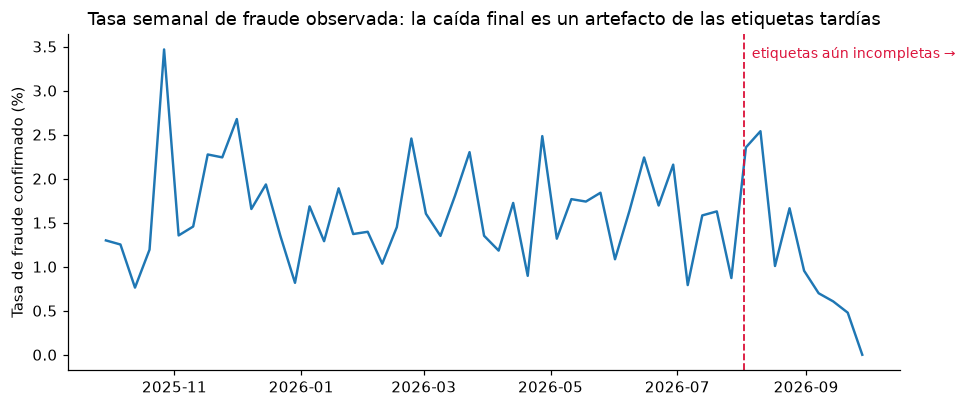

Transacciones con etiqueta madura: 45,484 de 54,253


In [15]:
base["etiqueta_madura"] = base["fecha_hora"] <= FECHA_MADUREZ
base["semana"] = base["fecha_hora"].dt.to_period("W").dt.start_time

semanal = (base.groupby("semana")
               .agg(transacciones=("monto", "size"), tasa_fraude=("es_fraude_confirmado", "mean")))

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(semanal.index, 100 * semanal["tasa_fraude"], lw=1.6, color="#1f77b4")
ax.axvline(FECHA_MADUREZ, color="crimson", ls="--", lw=1.2)
ax.text(FECHA_MADUREZ, ax.get_ylim()[1] * 0.96, "  etiquetas aún incompletas →", color="crimson", va="top", fontsize=9)
ax.set_ylabel("Tasa de fraude confirmado (%)")
ax.set_title("Tasa semanal de fraude observada: la caída final es un artefacto de las etiquetas tardías")
plt.tight_layout()
plt.show()
print(f"Transacciones con etiqueta madura: {base['etiqueta_madura'].sum():,} de {len(base):,}")

**División temporal.** Para evaluar un modelo que debe detectar fraude **en el futuro**, entrenamos con el pasado y probamos con lo que ocurrió después. Un corte aleatorio mezclaría las compras de un mismo cliente en ambos conjuntos y dejaría que el modelo "viera el futuro".

In [16]:
CORTE = pd.Timestamp("2026-05-01")

def partir(df):
    # Solo filas con etiqueta madura; entrenamiento antes del corte y prueba desde el corte
    d = df[df["etiqueta_madura"]]
    return d[d["fecha_hora"] < CORTE], d[d["fecha_hora"] >= CORTE]

entrena, prueba = partir(base)
pd.DataFrame({
    "conjunto": ["entrenamiento", "prueba"],
    "periodo": [f"{entrena['fecha_hora'].min():%Y-%m-%d} a {entrena['fecha_hora'].max():%Y-%m-%d}",
                f"{prueba['fecha_hora'].min():%Y-%m-%d} a {prueba['fecha_hora'].max():%Y-%m-%d}"],
    "transacciones": [len(entrena), len(prueba)],
    "fraudes": [int(entrena["es_fraude_confirmado"].sum()), int(prueba["es_fraude_confirmado"].sum())],
    "tasa de fraude (%)": [100 * entrena["es_fraude_confirmado"].mean(), 100 * prueba["es_fraude_confirmado"].mean()],
})

,conjunto,periodo,transacciones,fraudes,tasa de fraude (%)
0,entrenamiento,2025-10-01 a 2026-04-30,31630,518,1.64
1,prueba,2026-05-01 a 2026-08-01,13854,225,1.62


**Agregación.** Para describir el fenómeno resumimos las transacciones por hora del día y canal. Es una agregación con un costo que ya conocemos: **es irreversible** (conservamos la tabla por transacción) y **cambia lo que se ve**. La tasa semanal de la gráfica anterior ocultaría por completo que el riesgo se concentra en ciertas horas:

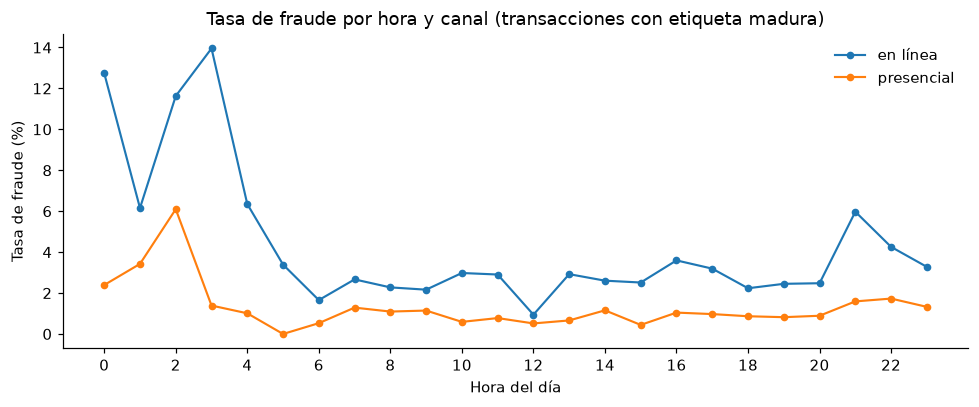

canal,en línea,presencial
hora_del_dia,,
0,102,209
1,65,146
2,43,82
3,43,72
4,63,99
5,118,203


In [17]:
modelado = base[base["etiqueta_madura"]]
por_hora = (modelado.groupby(["hora_del_dia", "canal"])
                    .agg(transacciones=("monto", "size"), fraudes=("es_fraude_confirmado", "sum"))
                    .reset_index())
por_hora["tasa_pct"] = 100 * por_hora["fraudes"] / por_hora["transacciones"]

fig, ax = plt.subplots(figsize=(9, 3.8))
for canal, d in por_hora.groupby("canal"):
    ax.plot(d["hora_del_dia"], d["tasa_pct"], marker="o", ms=4, lw=1.4, label=canal)
ax.set_xlabel("Hora del día")
ax.set_ylabel("Tasa de fraude (%)")
ax.set_xticks(range(0, 24, 2))
ax.set_title("Tasa de fraude por hora y canal (transacciones con etiqueta madura)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()
por_hora.pivot(index="hora_del_dia", columns="canal", values="transacciones").head(6)

Cada punto de la gráfica resume cientos de transacciones, y los de la madrugada **se apoyan en muy pocas** (véase la tabla de conteos): por eso las tasas por hora son más ruidosas de noche. Toda agregación debe ir acompañada de su **denominador**.

## 10. Fuga de información: el error que parece éxito

La sección 2 insistió en usar solo información disponible en el momento. Veamos qué pasa si la ignoramos. Construimos dos variables **con fuga**, que parecen razonables:

- `monto_z_global`: el z del monto calculado con **todas** las transacciones del cliente (incluye el futuro y la propia transacción).
- `contracargos_totales_cliente`: cuántos fraudes tiene el cliente **en total** (incluye el de la propia fila y los posteriores).

Comparamos la capacidad de detectar fraude (**precisión promedio**, que es la métrica apropiada cuando el fraude es raro) con y sin fuga, usando el mismo modelo y la misma división temporal:

In [18]:
base["monto_z_global"] = base.groupby("id_cliente")["log_monto"].transform(lambda s: (s - s.mean()) / s.std()).fillna(0.0)
base["contracargos_totales_cliente"] = base.groupby("id_cliente")["es_fraude_confirmado"].transform("sum")
entrena, prueba = partir(base)

VARIABLES = ["monto_z_cliente", "sin_historial", "ubicacion_inusual", "n_trans_24h",
             "tiene_contracargo_previo", "dispositivo_nuevo", "es_madrugada", "es_en_linea"]
VARIABLES_CON_FUGA = ["monto_z_global" if v == "monto_z_cliente" else
                      "contracargos_totales_cliente" if v == "tiene_contracargo_previo" else v for v in VARIABLES]

def evaluar(columnas, modelo):
    modelo.fit(entrena[columnas].astype(float), entrena["es_fraude_confirmado"])
    probabilidad = modelo.predict_proba(prueba[columnas].astype(float))[:, 1]
    return average_precision_score(prueba["es_fraude_confirmado"], probabilidad)

lineal = lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
base_azar = prueba["es_fraude_confirmado"].mean()

pd.DataFrame([
    ("Sin información (azar)", "-", base_azar),
    ("Variables correctas (solo el pasado)", "monto_z_cliente, tiene_contracargo_previo, ...", evaluar(VARIABLES, lineal())),
    ("Variables con fuga (usan todo el periodo)", "monto_z_global, contracargos_totales_cliente, ...", evaluar(VARIABLES_CON_FUGA, lineal())),
], columns=["escenario", "variables clave", "precisión promedio en prueba"]).round(3)

,escenario,variables clave,precisión promedio en prueba
0,Sin información (azar),-,0.02
1,Variables correctas (solo el pasado),"monto_z_cliente, tiene_contracargo_previo, ...",0.30
2,Variables con fuga (usan todo el periodo),"monto_z_global, contracargos_totales_cliente, ...",0.42


Con fuga, el modelo "mejora" notablemente, pero ese desempeño **no existiría en producción**: `contracargos_totales_cliente` ya contiene la respuesta de la propia fila. Es la razón por la que en la sección 2 cada regla decía "previas" o "confirmado antes". Y es un error **difícil de notar** si solo se mira la métrica: lo detectamos porque revisamos cómo se construyó cada variable.

> **Regla práctica.** Si un resultado es sospechosamente bueno, primero revisa la construcción de las variables. Y para cada variable, pregunta: *¿tendría este valor en el momento en que debo decidir?*

## 11. Entregables: diccionario, esquema y README

Cerramos la base con su documentación. El diccionario se **genera con código** a partir de metadatos declarados una sola vez; los rangos y los faltantes se calculan desde los datos, de modo que no puede quedar desactualizado.

Decisión sobre qué columnas entran a la base de análisis: **no incluimos `fecha_confirmacion`**. Solo existe *después* del evento y usarla como variable sería otra fuga. Tampoco las variables con fuga de la sección anterior: eran un experimento.

In [19]:
SIS_CLI, SIS_TIE, SIS_TRX, SIS_CON = ("Sistema de clientes", "Sistema de tiendas", "Sistema de transacciones", "Sistema de contracargos")

meta = {
    # variable: (tipo, unidad, descripcion, fuente, transformacion)
    "id_transaccion": ("Texto", "-", "Identificador único de la transacción (llave primaria)", SIS_TRX,
                       "Sin cambios; se eliminaron las filas duplicadas"),
    "fecha_hora": ("Fecha-hora", "aaaa-mm-dd hh:mm:ss", "Momento en que ocurrió la transacción (hora local, sin zona horaria declarada)", SIS_TRX,
                   "Convertida de texto a fecha-hora"),
    "id_cliente": ("Texto", "-", "Identificador del cliente (llave foránea a clientes)", SIS_TRX, "Sin cambios"),
    "segmento_cliente": ("Categórica", "-", "Segmento comercial del cliente (básico, preferente, premium)", SIS_CLI,
                         "Faltantes (≈3 % de los clientes) codificados como 'sin dato'; no se imputó con la moda"),
    "ciudad_habitual": ("Categórica", "-", "Ciudad de residencia habitual declarada por el cliente", SIS_CLI, "Sin cambios"),
    "id_tienda": ("Texto", "-", "Identificador de la tienda (llave foránea a tiendas)", SIS_TRX,
                  "Se excluyeron las transacciones cuya tienda no existe en el catálogo"),
    "ciudad_tienda": ("Categórica", "-", "Ciudad de la tienda (en tiendas en línea, la sede)", SIS_TIE, "Sin cambios"),
    "giro": ("Categórica", "-", "Giro comercial de la tienda", SIS_TIE, "Sin cambios"),
    "canal": ("Categórica", "-", "Canal de la compra: presencial o en línea", SIS_TRX, "Sin cambios"),
    "ciudad_transaccion": ("Categórica", "-", "Ciudad donde ocurrió la transacción", SIS_TRX,
                           "Escrituras distintas (CDMX, minúsculas, sin acento, espacios) normalizadas a ocho ciudades"),
    "id_dispositivo": ("Texto", "-", "Dispositivo desde el que se hizo la compra en línea", SIS_TRX,
                       "Vacío en compras presenciales (faltante estructural: no aplica); no se imputa"),
    "monto": ("Número", "pesos", "Importe de la transacción", SIS_TRX,
              "Se excluyeron las transacciones con monto menor o igual que cero (registradas en transacciones_excluidas.csv)"),
    "es_fraude_confirmado": ("Binaria", "0 / 1", "1 si el banco confirmó el fraude (existe contracargo) a la fecha de extracción", SIS_CON,
                             "Integrada con LEFT JOIN; es una variable a explicar con etiqueta tardía: solo es confiable si etiqueta_madura = True"),
    "etiqueta_madura": ("Sí/No", "-", "La transacción es anterior a fecha de extracción menos 60 días", "Derivada",
                        "Calculada para excluir del modelado las transacciones con etiqueta incompleta"),
    "monto_z_cliente": ("Número", "desviaciones estándar", "Qué tan atípico es el monto respecto al historial previo del cliente (logaritmo)", "Derivada",
                        "Solo con transacciones anteriores; requiere al menos 5; si no hay historial vale 0 y sin_historial = Sí"),
    "sin_historial": ("Sí/No", "-", "El cliente tenía menos de 5 transacciones previas", "Derivada", "Bandera que acompaña a monto_z_cliente"),
    "ubicacion_inusual": ("Sí/No", "-", "La ciudad de la transacción difiere de la ciudad habitual del cliente", "Derivada",
                          "Comparación de ciudad_transaccion con ciudad_habitual"),
    "n_trans_24h": ("Conteo", "transacciones", "Transacciones previas del cliente en las 24 horas anteriores", "Derivada",
                    "Ventana móvil por cliente, sin contar la transacción actual"),
    "tiene_contracargo_previo": ("Sí/No", "-", "El cliente tenía un contracargo confirmado antes de esta transacción", "Derivada",
                                 "Compara fecha_confirmacion con la fecha de la transacción (evita fuga)"),
    "dispositivo_nuevo": ("Sí/No", "-", "Compra en línea con un dispositivo no usado antes por el cliente", "Derivada",
                          "Primer uso del dispositivo con historial en línea previo; en compras presenciales vale No (no aplica); marca también como nuevo el segundo dispositivo legítimo"),
    "hora_del_dia": ("Entero", "hora (0-23)", "Hora de la transacción", "Derivada", "Extraída de fecha_hora"),
    "es_madrugada": ("Sí/No", "-", "La transacción ocurrió entre las 0:00 y las 5:59", "Derivada", "Calculada desde hora_del_dia"),
}

def rango(serie):
    s = serie.dropna()
    if s.empty:
        return "sin datos"
    if pd.api.types.is_bool_dtype(serie):
        return "verdadero o falso"
    if pd.api.types.is_datetime64_any_dtype(serie):
        return f"{s.min():%Y-%m-%d} a {s.max():%Y-%m-%d}"
    if pd.api.types.is_numeric_dtype(serie):
        if set(s.unique()) <= {0, 1}:
            return "0 o 1"
        return f"{s.min():.2f} a {s.max():.2f}"
    return f"{s.nunique()} valores distintos"

columnas_base = list(meta.keys())
base_analisis = base[columnas_base].copy()

filas = []
for col in columnas_base:
    tipo, unidad, desc, fuente, transf = meta[col]
    faltante = base_analisis[col].isna().mean()
    filas.append({"archivo": "transacciones_analisis.csv", "variable": col, "tipo": tipo, "unidad": unidad,
                  "valores_observados": rango(base_analisis[col]), "puede_estar_vacio": "Sí" if faltante > 0 else "No",
                  "porcentaje_faltante": round(100 * faltante, 1), "descripcion": desc, "fuente": fuente,
                  "transformacion_aplicada": transf})
diccionario = pd.DataFrame(filas)
diccionario[["variable", "tipo", "valores_observados", "porcentaje_faltante", "fuente"]]

,variable,tipo,valores_observados,porcentaje_faltante,fuente
0,id_transaccion,Texto,54253 valores distintos,0.00,Sistema de transacciones
1,fecha_hora,Fecha-hora,2025-10-01 a 2026-09-30,0.00,Sistema de transacciones
2,id_cliente,Texto,2000 valores distintos,0.00,Sistema de transacciones
3,segmento_cliente,Categórica,4 valores distintos,0.00,Sistema de clientes
4,ciudad_habitual,Categórica,8 valores distintos,0.00,Sistema de clientes
5,id_tienda,Texto,120 valores distintos,0.00,Sistema de transacciones
6,ciudad_tienda,Categórica,8 valores distintos,0.00,Sistema de tiendas
7,giro,Categórica,7 valores distintos,0.00,Sistema de tiendas
8,canal,Categórica,2 valores distintos,0.00,Sistema de transacciones
9,ciudad_transaccion,Categórica,8 valores distintos,0.00,Sistema de transacciones


In [20]:
base_analisis.to_csv(RAIZ / "datos/procesados/transacciones_analisis.csv", index=False)
diccionario.to_csv(RAIZ / "datos/diccionario_datos.csv", index=False, encoding="utf-8")

esquema = '''Esquema de datos (SQLite: datos/procesados/fraude.sqlite)

clientes(id_cliente PK, segmento_cliente, fecha_alta, ciudad_habitual)
tiendas(id_tienda PK, ciudad_tienda, giro)
transacciones(id_transaccion PK, fecha_hora, id_cliente FK -> clientes, id_tienda FK -> tiendas,
              canal, ciudad_transaccion, id_dispositivo, monto)          monto > 0
contracargos(id_transaccion PK, FK -> transacciones, fecha_confirmacion)  0 o 1 por transaccion

Tabla de analisis: transacciones_analisis.csv (una fila por transaccion), obtenida con una consulta SQL
(JOIN de clientes y tiendas, LEFT JOIN de contracargos) y variables derivadas calculadas solo con el pasado.
'''
(RAIZ / "documentos/esquema_datos.txt").write_text(esquema, encoding="utf-8")
con.close()

n_madura = int(base["etiqueta_madura"].sum())
readme = f'''# Detección de transacciones fraudulentas: de la pregunta a la base de datos (ejemplo con datos simulados)

Ejemplo didáctico de la Unidad 4 (Seminario de Proyecto I, MCDI). **Los datos son simulados**: no corresponden a ninguna persona ni institución real, y no permiten sacar conclusiones sobre fraude real.

## Pregunta de investigación
¿Qué factores permiten identificar de manera temprana las transacciones financieras fraudulentas en plataformas digitales?

## Objetivos e hipótesis
- **Objetivo general:** analizar los factores transaccionales y de usuario que inciden en la detección de fraude con modelos de ciencia de datos.
- **Hipótesis general:** integrar variables transaccionales y de usuario en modelos de aprendizaje automático mejora la detección de fraude.
- **OE1 / H1:** identificar variables transaccionales asociadas al fraude / montos atípicos y ubicaciones inusuales aumentan la probabilidad de fraude.
- **OE2 / H2:** evaluar características del usuario / historiales irregulares y dispositivos no habituales aumentan el riesgo.
- **OE3 / H3:** comparar algoritmos / los ensambles superan a los modelos lineales.

## Origen de los datos
- **Fuente:** simulación reproducible (semilla {SEMILLA}) en el notebook 04 de la Unidad 4. Extracción simulada al {FECHA_EXTRACCION:%Y-%m-%d}.
- **Cuatro sistemas:** clientes, tiendas, transacciones y contracargos.
- **Muestreo:** por conglomerados (2,000 clientes; todas sus transacciones), del {INICIO:%Y-%m-%d} al {FIN:%Y-%m-%d}.
- **Cobertura:** {len(base_analisis):,} transacciones; {int(base_analisis["es_fraude_confirmado"].sum())} con fraude confirmado.

## Estructura
```
datos/originales/       archivos tal como los entregan los sistemas (no se modifican)
datos/procesados/       fraude.sqlite, transacciones_analisis.csv, transacciones_excluidas.csv
datos/diccionario_datos.csv
documentos/esquema_datos.txt
README.md
```

## Transformaciones (el detalle está en el diccionario)
1. Se eliminaron {n_duplicadas} filas duplicadas.
2. Se normalizó la escritura de {n_ciudades} nombres de ciudad.
3. Se excluyeron {len(excluidas)} transacciones inválidas (monto no positivo o tienda inexistente), registradas en `transacciones_excluidas.csv`.
4. Los {n_sin_segmento} clientes sin segmento se codificaron como `sin dato`.
5. Se cargó un modelo relacional en SQLite (llaves primarias, foráneas y reglas de validez) y se integró en una tabla plana con SQL.
6. Se derivaron variables de las hipótesis usando **solo información anterior** a cada transacción.
7. Etiquetas tardías: {n_madura:,} transacciones tienen etiqueta madura (anteriores a {FECHA_MADUREZ:%Y-%m-%d}); el resto se conserva marcado y se excluye del modelado.
8. `id_dispositivo` vacío en compras presenciales es un faltante estructural: no se imputa.

## Limitaciones
- Datos simulados: los resultados reflejan el mecanismo que programamos, no el mundo real.
- La etiqueta de fraude es tardía; los fraudes recientes aparecen como 0 hasta que se confirman.
- Las transacciones de un mismo cliente no son independientes (muestreo por conglomerados): por eso la validación es temporal.
- `dispositivo_nuevo` también marca como nuevo el segundo dispositivo legítimo de un cliente.
- No se incluye `fecha_confirmacion` en la base de análisis: solo existe después del evento.
'''
(RAIZ / "README.md").write_text(readme, encoding="utf-8")
print("Archivos de salida:")
for ruta in sorted(RAIZ.rglob("*")):
    if ruta.is_file():
        print(f"  {str(ruta.relative_to(RAIZ)):45s} {ruta.stat().st_size / 1024:>9,.1f} KB")

Archivos de salida:
  README.md                                           3.1 KB
  datos/diccionario_datos.csv                         4.7 KB
  datos/originales/clientes.csv                      73.6 KB
  datos/originales/contracargos.csv                  17.5 KB
  datos/originales/origen.txt                         0.2 KB
  datos/originales/tiendas.csv                        3.4 KB
  datos/originales/transacciones.csv              3,930.6 KB
  datos/procesados/fraude.sqlite                  5,652.0 KB
  datos/procesados/transacciones_analisis.csv     9,474.6 KB
  datos/procesados/transacciones_excluidas.csv       24.8 KB
  documentos/esquema_datos.txt                        0.6 KB


## 12. ¿La base permite contrastar las hipótesis?

El objetivo de este notebook **no** es contrastar las hipótesis, sino comprobar que la base **contiene lo necesario** para hacerlo y que las variables se comportan de manera coherente. Hacemos una primera mirada descriptiva con las transacciones de etiqueta madura.

**H1 y H2: tasa de fraude según cada variable.**

In [21]:
maduro = base[base["etiqueta_madura"]]

def tasas(variable, titulo, umbral=None):
    serie = (maduro[variable] > umbral) if umbral is not None else maduro[variable]
    t = maduro.groupby(serie)["es_fraude_confirmado"].agg(transacciones="size", fraudes="sum")
    t["tasa de fraude (%)"] = 100 * t["fraudes"] / t["transacciones"]
    t.index = [f"{titulo}: {'sí' if i else 'no'}" for i in t.index]
    return t

resumen = pd.concat([
    tasas("monto_z_cliente", "H1 monto atípico (z > 2)", umbral=2),
    tasas("ubicacion_inusual", "H1 ubicación inusual"),
    tasas("n_trans_24h", "H1 una o más transacciones previas en 24 h", umbral=0),
    tasas("tiene_contracargo_previo", "H2 contracargo previo"),
    tasas("dispositivo_nuevo", "H2 dispositivo nuevo"),
    tasas("es_madrugada", "H2 madrugada"),
])
resumen.round(2)

,transacciones,fraudes,tasa de fraude (%)
H1 monto atípico (z > 2): no,44018,674,1.53
H1 monto atípico (z > 2): sí,1466,69,4.71
H1 ubicación inusual: no,42679,571,1.34
H1 ubicación inusual: sí,2805,172,6.13
H1 una o más transacciones previas en 24 h: no,40838,351,0.86
H1 una o más transacciones previas en 24 h: sí,4646,392,8.44
H2 contracargo previo: no,40928,628,1.53
H2 contracargo previo: sí,4556,115,2.52
H2 dispositivo nuevo: no,43054,668,1.55
H2 dispositivo nuevo: sí,2430,75,3.09


**H3: modelos lineales frente a ensambles.** La base ya permite compararlos con **la misma división temporal** y la misma métrica. Comparamos una regresión logística con un ensamble de árboles (*gradient boosting*):

In [22]:
ensamble = lambda: HistGradientBoostingClassifier(max_depth=3, max_iter=150, learning_rate=0.1, random_state=SEMILLA)

entrena, prueba = partir(base)
pd.DataFrame([
    ("Sin información (azar)", prueba["es_fraude_confirmado"].mean()),
    ("Regresión logística", evaluar(VARIABLES, lineal())),
    ("Ensamble de árboles (gradient boosting)", evaluar(VARIABLES, ensamble())),
], columns=["modelo", "precisión promedio en prueba"]).round(3)

,modelo,precisión promedio en prueba
0,Sin información (azar),0.02
1,Regresión logística,0.30
2,Ensamble de árboles (gradient boosting),0.31


> **No interpretes esto como evidencia a favor o en contra de H1, H2 o H3.** Los datos son simulados con un mecanismo que programamos nosotros: que ciertos factores aparezcan asociados al fraude, o que un modelo supere a otro, depende de ese mecanismo y no del mundo real. Lo que sí muestra esta sección es que **la base está completa y lista**: cada hipótesis tiene sus variables, la variable a explicar tiene una etiqueta confiable, y la división temporal permite evaluar sin fuga.

### Lista de buenas prácticas (cómo la cumple este ejemplo)

| Requisito | Dónde se cumple en este ejemplo |
|---|---|
| Archivo de base de datos creado | `datos/procesados/fraude.sqlite` (relacional) y `transacciones_analisis.csv` (tabla de análisis) |
| Herramienta utilizada | SQLite (DBMS) y Python (pandas) |
| Alineación metodológica explícita | Secciones 1 y 2: pregunta → objetivo → hipótesis → variable → regla de medición |
| Evaluación del origen de datos | Secciones 4 y 5: población, marco, diseño de muestreo y problemas de la extracción |
| Variables incluidas listadas | `diccionario_datos.csv` (tipo, unidad, rango y % faltante por variable) |
| Transformaciones documentadas | Columna `transformacion_aplicada`, `transacciones_excluidas.csv` y README |
| Diccionario de datos completo | `datos/diccionario_datos.csv` |
| Video corto y PDF (Evidencia 4A) | **Los produces tú** con tu propia base (aquí no aplican) |

### Lo que debes replicar en tu proyecto

1. Parte de la **pregunta y las hipótesis**; cada concepto necesita una **variable y una regla de medición**.
2. Decide la **estructura** (empieza con una tabla; divide si hay una razón) y la **unidad de análisis**.
3. Planea la **recolección y el muestreo**, sobre todo si el fenómeno es raro.
4. **Diagnostica antes de limpiar**; registra lo excluido y comprueba que cada decisión haga lo que dices.
5. Distingue los **faltantes** (estructural, aleatorio, por falta de historial) y trátalos distinto.
6. Calcula cada variable **solo con información disponible en el momento**; cuidado con las etiquetas tardías.
7. Valida con una **división temporal** y documenta todo en el diccionario y el README.